# Занятие 6. Сохранение и применение модели

В предыдущем занятии мы выбрали алгоритм и правило обработки заявок. Теперь рассмотрим другой рабочий момент: приходит новый пакет заказов, у которых ещё нет исхода. Нужно получить те же вероятности после перезапуска среды, проверить форму входа и передать допустимое число заявок на дополнительную обработку. Поэтому сохраняем целый конвейер подготовки и модели, а рядом — JSON с признаками, версиями, порогом и ограничениями.

Этот ноутбук автономен: он сам повторяет обучение на раннем периоде и выбор по validation тем же правилом, не читая переменные и артефакты пятого занятия. Отложенный test здесь не используется. Сохранение через joblib основано на механизме pickle, поэтому загружаем только файл, который только что создали сами; перенос между версиями scikit-learn не обещается. Пример работает локально, без сервера или API.

Сохранённые выводы показывают весь путь: подготовку решения, запись и загрузку, проверку новых заявок, обработанные ошибки ввода и наблюдение за входными данными и оценками риска. Пока метки по новым заявкам не созрели, распределение оценок и пропусков не является показателем точности модели. При чтении кода отделяйте три проверки: файл технически загружается, вход соответствует схеме, а качество прогнозов на будущем периоде остаётся вопросом для последующей оценки. Успех одной проверки не заменяет остальные. Особенно внимательно рассмотрите те примеры, где запрос обрабатывается без ошибки, но его категория не встречалась при обучении. Такой результат годится для продолжения работы и одновременно требует диагностического наблюдения.

## 1. Повторяем зафиксированную процедуру выбора

Снова используем только двенадцать признаков, обучающий период до 25 июля и validation с 1 августа до 24 сентября. Промежуток обеспечивает зрелость меток. Три содержательных кандидата и Dummy имеют фиксированные параметры. Алгоритм выбираем по AP, порог — по условной стоимости FN=5 и FP=1 на validation, затем ограничиваем очередь десятью процентами пакета. Это самостоятельное воспроизведение процедуры, без обращения к test.

**Все зависимости и рабочая папка**

Импортируем библиотеки один раз и задаём имена полей. Для числовых и категориальных колонок сохраняем отдельные списки. Папка `outputs/06` содержит только результат этого занятия: конвейер, метаданные, пакетные прогнозы и диагностический журнал.

In [1]:
# Шаг М2.06.01 — Все зависимости и рабочая папка
from pathlib import Path
from datetime import datetime, timezone, timedelta
import sys
import json
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import average_precision_score

NUMERIC = ['distance_km', 'items_count', 'order_amount', 'warehouse_load',
           'customer_prior_orders', 'promised_days', 'order_hour']
CATEGORICAL = ['city', 'product_category', 'delivery_type',
               'weather_forecast', 'is_weekend']
FEATURES = NUMERIC + CATEGORICAL
OUT = Path('outputs/06')
OUT.mkdir(parents=True, exist_ok=True)
print('Каталог результата:', OUT, 'Признаков:', len(FEATURES))

Каталог результата: outputs\06 Признаков: 12


**Журнал и срок хранения**

При старте удаляем только собственные журналы вида `delivery_*.log` старше 30 дней в `outputs/06`. Затем создаём журнал текущего запуска. Дата формируется в UTC — единой временной шкале, удобной для сравнения возраста файлов без зависимости от местного часового пояса. Дата формируется в UTC — единой временной шкале, удобной для сравнения возраста файлов без зависимости от местного часового пояса. Дата формируется в UTC — единой временной шкале, удобной для сравнения возраста файлов без зависимости от местного часового пояса. Дата формируется в UTC — единой временной шкале, удобной для сравнения возраста файлов без зависимости от местного часового пояса. Записи предназначены для диагностики пакетного применения: количество строк, неизвестных категорий и ошибок схемы, без персональных идентификаторов и значений отдельных заказов.

In [2]:
# Шаг М2.06.02 — Журнал и срок хранения
now = datetime.now(timezone.utc)
for old_log in OUT.glob('delivery_*.log'):
    changed = datetime.fromtimestamp(old_log.stat().st_mtime, timezone.utc)
    if changed < now - timedelta(days=30):
        old_log.unlink()
logger = logging.getLogger('delivery_risk_lesson06')
logger.setLevel(logging.INFO)
for handler in list(logger.handlers):
    logger.removeHandler(handler)
    handler.close()
log_path = OUT / f'delivery_{now:%Y%m%d}.log'
handler = logging.FileHandler(log_path, encoding='utf-8')
handler.setFormatter(logging.Formatter('%(asctime)s %(levelname)s %(message)s'))
logger.addHandler(handler)
logger.info('Запуск занятия 06; срок хранения журналов 30 дней')
print('Журнал:', log_path)

Журнал: outputs\06\delivery_20261019.log


**Ранние и проверочные заказы**

Читаем тот же синтетический CSV и выделяем только train и validation. Явный список признаков исключает служебные метки времени, идентификаторы и сведения после доставки. Проверяем, что все метки выбранных периодов были доступны вовремя.

In [3]:
# Шаг М2.06.03 — Ранние и проверочные заказы
data = pd.read_csv('data/delivery_risk.csv', parse_dates=['order_ts', 'label_available_at'])
train = data.loc[data['order_ts'] < pd.Timestamp('2026-07-25')].copy()
valid = data.loc[(data['order_ts'] >= pd.Timestamp('2026-08-01')) &
                 (data['order_ts'] < pd.Timestamp('2026-09-24'))].copy()
assert (train['label_available_at'] <= pd.Timestamp('2026-08-01')).all()
assert (valid['label_available_at'] <= pd.Timestamp('2026-10-01')).all()
assert not {'actual_delay_hours', 'compensation_paid', 'request_id',
            'customer_id', 'order_ts', 'label_available_at'} & set(FEATURES)
X_train, y_train = train[FEATURES], train['late_delivery'].astype(int)
X_valid, y_valid = valid[FEATURES], valid['late_delivery'].astype(int)
print('Train:', len(train), 'Validation:', len(valid))

Train: 7863 Validation: 2072


**Целый конвейер для каждого алгоритма**

Функция создаёт подготовку внутри Pipeline. Медиана и индикатор пропуска работают с числовыми полями, мода и one-hot — с категориальными. Масштабирование требуется только логистической регрессии. Так сохраняемый объект позже будет включать изученные на train преобразования.

In [4]:
# Шаг М2.06.04 — Целый конвейер для каждого алгоритма
def make_prepare(scale):
    numeric = [('impute', SimpleImputer(strategy='median', add_indicator=True))]
    if scale:
        numeric.append(('scale', StandardScaler()))
    return ColumnTransformer([
        ('numeric', Pipeline(numeric), NUMERIC),
        ('categorical', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), CATEGORICAL)
    ])

models = {
    'logistic': Pipeline([('prepare', make_prepare(True)),
                          ('model', LogisticRegression(C=1.0, max_iter=1000, random_state=42))]),
    'tree': Pipeline([('prepare', make_prepare(False)),
                      ('model', DecisionTreeClassifier(max_depth=5, min_samples_leaf=50, random_state=42))]),
    'forest': Pipeline([('prepare', make_prepare(False)),
                        ('model', RandomForestClassifier(n_estimators=120, max_depth=9,
                                                         min_samples_leaf=15, max_features=0.7,
                                                         n_jobs=2, random_state=42))]),
    'dummy': DummyClassifier(strategy='prior')
}
print('Кандидаты:', ', '.join(models))

Кандидаты: logistic, tree, forest, dummy


**Автономный выбор по AP**

Обучаем кандидатов на train и считаем AP на одних и тех же validation строках. Лидера определяет максимальный AP с однозначным разрешением равенства. Это та же процедура, что раньше, но переменные предыдущего ноутбука не нужны.

In [5]:
# Шаг М2.06.05 — Автономный выбор по AP
valid_prob = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    valid_prob[name] = model.predict_proba(X_valid)[:, 1]
comparison = pd.DataFrame([
    {'модель': name, 'AP_validation': average_precision_score(y_valid, prob)}
    for name, prob in valid_prob.items()
]).sort_values(['AP_validation', 'модель'], ascending=[False, True]).reset_index(drop=True)
winner_name = str(comparison.iloc[0]['модель'])
pipeline = models[winner_name]
winner_prob = valid_prob[winner_name]
assert winner_name != 'dummy'
display(comparison)
print('Сохраняемый кандидат:', winner_name)

,модель,AP_validation
0,forest,0.321099
1,logistic,0.312494
2,tree,0.296406
3,dummy,0.115347


Сохраняемый кандидат: forest


**Порог и лимит для нового пакета**

На validation перебираем пороги от 0,05 до 0,95 с шагом 0,01. Считаем условную цену пропуска пять единиц и лишнего сигнала одну. При равной цене предпочитаем более высокий порог. Лимит обработки — не более 10% строк переданного пакета.

In [6]:
# Шаг М2.06.06 — Порог и лимит для нового пакета
cost_rows = []
for t in np.round(np.arange(0.05, 0.951, 0.01), 2):
    alert = winner_prob >= t
    fp = int(((y_valid == 0) & alert).sum())
    fn = int(((y_valid == 1) & ~alert).sum())
    cost_rows.append((float(t), fp + 5 * fn))
cost_table = pd.DataFrame(cost_rows, columns=['порог', 'условная_стоимость'])
threshold = float(cost_table.sort_values(['условная_стоимость', 'порог'],
                                         ascending=[True, False]).iloc[0]['порог'])
capacity_share = 0.10
print('Модель:', winner_name, 'Порог:', threshold, 'Лимит:', capacity_share)

Модель: forest Порог: 0.23 Лимит: 0.1


Мы получили тот же тип решения без зависимостей от пятого ноутбука: обученный Pipeline, имя алгоритма, validation AP, порог и лимит. Отложенный период не использовался. Теперь упакуем решение так, чтобы после перезапуска среда знала и параметры модели, и условия применения.

## 2. Артефакт, метаданные и проверка загрузки

`joblib` сохраняет весь Pipeline в одном локальном файле. JSON — текстовый формат объектов и массивов. Он хранит человекочитаемый контракт: список признаков, периоды, параметры политики, версии библиотек и короткую карточку ограничений. Загрузим только созданный нами файл и сравним вероятности до и после восстановления. Механизм joblib использует pickle, поэтому чужой файл загружать небезопасно; одинаковая работа между разными версиями scikit-learn не гарантируется.

**Словарь категорий обучения**

Сохраняем уровни категорий, которые встречались в train. Неизвестный город будет принят кодировщиком, но отдельный контроль входа сможет показать, что он новый. Для пропусков в городе и погоде оставляем явную возможность отсутствующего значения.

In [7]:
# Шаг М2.06.07 — Словарь категорий обучения
known_categories = {
    col: sorted(str(value) for value in X_train[col].dropna().unique())
    for col in CATEGORICAL
}
for col, levels in known_categories.items():
    print(col, 'известных уровней:', len(levels))
print('Новый город в train:', 'Новый город' in known_categories['city'])

city известных уровней: 16
product_category известных уровней: 9
delivery_type известных уровней: 3
weather_forecast известных уровней: 3
is_weekend известных уровней: 2
Новый город в train: False


**Карточка модели и политика**

Формируем метаданные для самостоятельного чтения артефакта. Здесь есть имя алгоритма, версия схемы, версии библиотек, границы обучения и проверки, метрика выбора, параметры действия и ограничения. Карточка прямо сообщает, что данные синтетические и эффект вмешательства не измерен.

In [8]:
# Шаг М2.06.08 — Карточка модели и политика
metadata = {
    'artifact_name': 'delivery_risk_pipeline', 'schema_version': 1,
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'model': winner_name, 'features': FEATURES,
    'numeric_features': NUMERIC, 'categorical_features': CATEGORICAL,
    'known_categories': known_categories,
    'train_end_exclusive': '2026-07-25',
    'validation_start': '2026-08-01', 'validation_end_exclusive': '2026-09-24',
    'test_start_reserved': '2026-10-01',
    'selection_metric': 'average_precision_validation',
    'validation_ap': float(comparison.iloc[0]['AP_validation']),
    'threshold': threshold, 'capacity_share': capacity_share,
    'cost_false_negative': 5, 'cost_false_positive': 1,
    'versions': {'python': sys.version.split()[0],
                 'scikit_learn': sklearn.__version__,
                 'pandas': pd.__version__, 'numpy': np.__version__,
                 'joblib': joblib.__version__},
    'model_card': {
        'purpose': 'Оценка риска задержки при оформлении заказа',
        'data': 'Синтетические заказы 2026 года',
        'target': 'late_delivery; становится доступна через семь дней',
        'limitations': ['Условные цены ошибок, а не измеренный экономический эффект',
                        'Качество в новых городах и будущих периодах требует проверки',
                        'Доля и состав заказов могут меняться со временем']
    }
}
print('Схема:', metadata['schema_version'], 'Версия sklearn:', metadata['versions']['scikit_learn'])

Схема: 1 Версия sklearn: 1.8.0


**Сохраняем Pipeline и JSON**

Записываем подготовку вместе с моделью и рядом человекочитаемые метаданные. Оба файла относятся к одной версии решения. В коде нет выгрузки на внешний сервис или тяжёлых загрузок.

In [9]:
# Шаг М2.06.09 — Сохраняем Pipeline и JSON
model_path = OUT / 'delivery_pipeline.joblib'
meta_path = OUT / 'delivery_metadata.json'
joblib.dump(pipeline, model_path)
meta_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
logger.info('Артефакт сохранён: модель=%s, схема=%s', winner_name, metadata['schema_version'])
print(model_path, model_path.stat().st_size, 'байт')
print(meta_path, meta_path.stat().st_size, 'байт')

outputs\06\delivery_pipeline.joblib 2346811 байт
outputs\06\delivery_metadata.json 2977 байт


**Загружаем только собственный файл**

Восстанавливаем только путь `model_path`, который только что создал этот ноутбук. Затем читаем JSON и проверяем ожидаемый набор признаков и версию scikit-learn. Если версия среды изменилась, безопаснее пересоздать и повторно проверить артефакт.

In [10]:
# Шаг М2.06.10 — Загружаем только собственный файл
loaded = joblib.load(model_path)
loaded_meta = json.loads(meta_path.read_text(encoding='utf-8'))
assert loaded_meta['features'] == FEATURES
assert loaded_meta['versions']['scikit_learn'] == sklearn.__version__
assert isinstance(loaded, Pipeline)
print('Загружено:', type(loaded).__name__, 'модель:', loaded_meta['model'])

Загружено: Pipeline модель: forest


**Round-trip вероятностей**

Сравниваем вероятности на одних и тех же validation признаках до сохранения и после загрузки. Равенство с точностью до численного допуска подтверждает, что конвейер сохранил и подготовку, и алгоритм. Это инженерная проверка файла, не новая оценка качества.

In [11]:
# Шаг М2.06.11 — Round-trip вероятностей
before = pipeline.predict_proba(X_valid.head(50))[:, 1]
after = loaded.predict_proba(X_valid.head(50))[:, 1]
assert np.allclose(before, after, rtol=0, atol=1e-12)
print('Максимальное расхождение:', float(np.max(np.abs(before - after))))

Максимальное расхождение: 5.551115123125783e-17


**Стабильность пакетного расчёта**

Проверяем, что вероятности ста строк одинаковы при прогнозе одним пакетом и двумя частями в том же порядке. Это защищает от случайной зависимости оценки отдельной заявки от размера переданного DataFrame. Правило ёмкости, напротив, сознательно зависит от полного пакета.

In [12]:
# Шаг М2.06.12 — Стабильность пакетного расчёта
sample = X_valid.head(100)
whole = loaded.predict_proba(sample)[:, 1]
parts = np.concatenate([loaded.predict_proba(sample.iloc[:40])[:, 1],
                        loaded.predict_proba(sample.iloc[40:])[:, 1]])
assert np.allclose(whole, parts, rtol=0, atol=1e-12)
print('Стабильных вероятностей:', len(whole), 'Расхождение:', np.max(np.abs(whole - parts)))

Стабильных вероятностей: 100 Расхождение: 5.551115123125783e-17


Конвейер и метаданные сохранены и загружены локально. Вероятности совпали после round-trip и не зависят от разбиения входа на части. Следующий раздел покажет, как защитить этот объект от неверной схемы заявки и что делать с неизвестными категориями.

## 3. Схема новых заявок и обработка ошибок

Новая заявка содержит ровно двенадцать признаков и не содержит метки. Числовые пропуски допустимы, поскольку Pipeline умеет их заполнять; текстовые пропуски допустимы только для города и прогноза погоды, где они есть в учебной схеме. Пустые строки, нечисловые значения в числовых полях и явно невозможные диапазоны отклоняем до прогноза. Незнакомые категории допускаем, но отмечаем как диагностический сигнал.

**Диапазоны и обязательные поля**

Задаём широкие физически осмысленные границы для числовых полей. Они служат контролем явных ошибок ввода, а не попыткой ограничить модель обучающими минимумами. Например, расстояние немного больше виденного на train допустимо, но отрицательное расстояние — нет.

In [13]:
# Шаг М2.06.13 — Диапазоны и обязательные поля
RANGES = {
    'distance_km': (0, 2000), 'items_count': (1, 50),
    'order_amount': (0, 1_000_000), 'warehouse_load': (0, 2),
    'customer_prior_orders': (0, 1000), 'promised_days': (1, 30),
    'order_hour': (0, 23)
}
INTEGER_FEATURES = {'items_count', 'customer_prior_orders', 'promised_days', 'order_hour'}
OPTIONAL_CATEGORICAL = {'city', 'weather_forecast'}
print('Диапазонов:', len(RANGES), 'Обязательных категориальных:',
      len(set(CATEGORICAL) - OPTIONAL_CATEGORICAL))

Диапазонов: 7 Обязательных категориальных: 3


**Проверяющая функция**

Функция принимает DataFrame, сверяет точные имена полей, проверяет типы, пустые значения и диапазоны. Она возвращает копию в фиксированном порядке колонок. Ошибка содержит понятное название поля, а диагностический журнал отмечает отказ без записи содержимого заявки.

In [14]:
# Шаг М2.06.14 — Проверяющая функция
def validate_requests(frame):
    if not isinstance(frame, pd.DataFrame):
        logger.warning('Отклонён вход: ожидался DataFrame')
        raise TypeError('Ожидается pandas DataFrame')
    if not frame.columns.is_unique:
        logger.warning('Отклонена схема: повторяющиеся имена колонок')
        raise ValueError('Схема: повторяющиеся имена колонок')
    if not frame.columns.is_unique:
        logger.warning('Отклонена схема: повторяющиеся имена колонок')
        raise ValueError('Схема: повторяющиеся имена колонок')
    if not frame.columns.is_unique:
        logger.warning('Отклонена схема: повторяющиеся имена колонок')
        raise ValueError('Схема: повторяющиеся имена колонок')
    if not frame.columns.is_unique:
        logger.warning('Отклонена схема: повторяющиеся имена колонок')
        raise ValueError('Схема: повторяющиеся имена колонок')
    missing = sorted(set(FEATURES) - set(frame.columns))
    extra = sorted(set(frame.columns) - set(FEATURES))
    if missing or extra:
        logger.warning('Отклонена схема: отсутствуют=%s, лишние=%s', missing, extra)
        raise ValueError(f'Схема: отсутствуют {missing}; лишние {extra}')
    result = frame[FEATURES].copy()
    if result.empty:
        logger.warning('Отклонён пустой пакет')
        raise ValueError('Пакет заявок пуст')
    for col in NUMERIC:
        original = result[col]
        converted = pd.to_numeric(original, errors='coerce')
        if (original.notna() & converted.isna()).any():
            logger.warning('Отклонено нечисловое поле: %s', col)
            raise ValueError(f'{col}: ожидается число или пропуск')
        low, high = RANGES[col]
        if ((converted < low) | (converted > high)).fillna(False).any():
            logger.warning('Отклонено значение вне диапазона: %s', col)
            raise ValueError(f'{col}: допустимый диапазон {low}..{high}')
        if col in INTEGER_FEATURES and ((converted.dropna() % 1) != 0).any():
            logger.warning('Отклонено дробное значение: %s', col)
            raise ValueError(f'{col}: ожидается целое число')
        result[col] = converted.astype(float)
    for col in CATEGORICAL:
        present = result[col].dropna()
        if not present.map(lambda value: isinstance(value, str) and bool(value.strip())).all():
            logger.warning('Отклонено пустое или нестроковое поле: %s', col)
            raise ValueError(f'{col}: ожидается непустая строка')
        if col not in OPTIONAL_CATEGORICAL and result[col].isna().any():
            logger.warning('Отклонён обязательный пропуск: %s', col)
            raise ValueError(f'{col}: пропуск недопустим')
    return result

print('Контроль входа готов')

Контроль входа готов


**Пакет без метки и утечек**

Берём несколько строк только с разрешёнными признаками, имитируя новые заявки. У первой заменяем город на ранее неизвестный. Цель, фактическая задержка, компенсация, идентификаторы и временные служебные поля в пакет не входят.

In [15]:
# Шаг М2.06.15 — Пакет без метки и утечек
new_requests = X_valid.head(8).reset_index(drop=True).copy()
new_requests.loc[0, 'city'] = 'Новый город'
assert list(new_requests.columns) == FEATURES
assert 'late_delivery' not in new_requests.columns
display(new_requests.head(3))

,distance_km,items_count,order_amount,warehouse_load,customer_prior_orders,promised_days,order_hour,city,product_category,delivery_type,weather_forecast,is_weekend
0,18.1,2,NaN,1.327,6,4,0,Новый город,Спорт,Пункт выдачи,Ясно,Да
1,592.7,4,650.0,0.705,6,3,0,Новосибирск,Продукты,Обычная,Ясно,Да
2,430.6,1,3160.0,0.601,2,3,1,Воронеж,Обувь,Обычная,Ясно,Да


**Сигналы неизвестных категорий**

Сравниваем непустые категориальные значения пакета со словарём train. Незнакомые уровни не блокируют прогноз, потому что OneHotEncoder настроен на игнорирование. Возвращаем число таких значений по полям как диагностический признак изменения входного потока.

In [16]:
# Шаг М2.06.16 — Сигналы неизвестных категорий
def unknown_categories(frame, category_dictionary):
    return {col: int((frame[col].notna() &
                      ~frame[col].isin(category_dictionary[col])).sum())
            for col in CATEGORICAL}

checked_new = validate_requests(new_requests)
unknown = unknown_categories(checked_new, loaded_meta['known_categories'])
print('Незнакомые категории по полям:', unknown)
assert unknown['city'] >= 1

Незнакомые категории по полям: {'city': 1, 'product_category': 0, 'delivery_type': 0, 'weather_forecast': 0, 'is_weekend': 0}


**Правило действия и применение**

Нетривиальная функция сначала проверяет пакет, затем считает вероятности и выбирает не более 10% строк с риском выше порога. В результате сохраняем риск и сигнал, а в журнал — размер пакета, число сигналов, пропусков и неизвестных категорий. Сами заявки в журнал не попадают.

In [17]:
# Шаг М2.06.17 — Правило действия и применение
def apply_saved_solution(frame, model, info):
    clean = validate_requests(frame)
    risk = model.predict_proba(clean)[:, 1]
    limit = int(np.floor(len(clean) * info['capacity_share']))
    alert = np.zeros(len(clean), dtype=bool)
    order = np.argsort(-risk, kind='stable')
    chosen = order[risk[order] >= info['threshold']][:limit]
    alert[chosen] = True
    unknown = unknown_categories(clean, info['known_categories'])
    logger.info('Прогноз: строк=%d, сигналов=%d, пропусков=%d, неизвестных_категорий=%s',
                len(clean), int(alert.sum()), int(clean.isna().sum().sum()), unknown)
    return pd.DataFrame({'риск_задержки': risk, 'передать_на_обработку': alert},
                        index=clean.index)

new_result = apply_saved_solution(new_requests, loaded, loaded_meta)
display(new_result)

,риск_задержки,передать_на_обработку
0,0.123819,False
1,0.224564,False
2,0.070469,False
3,0.127504,False
4,0.267176,False
5,0.216404,False
6,0.201538,False
7,0.188527,False


**Обработанные ошибки входа**

Проверяем четыре плохих запроса отдельно: отсутствующее поле, текст вместо количества, невозможный час и повтор имени колонки. Каждую ошибку ловим и показываем, не прерывая остальные примеры. Это демонстрация контрактного отказа, а не исправление данных молча.

In [18]:
# Шаг М2.06.18 — Обработанные ошибки входа
bad_cases = {
    'нет поля': new_requests.drop(columns=['distance_km']),
    'текст вместо числа': new_requests.assign(items_count='много'),
    'час вне диапазона': new_requests.assign(order_hour=29),
    'повтор имени колонки': pd.concat([new_requests, new_requests[['city']]], axis=1),
    'повтор имени колонки': pd.concat([new_requests, new_requests[['city']]], axis=1),
    'повтор имени колонки': pd.concat([new_requests, new_requests[['city']]], axis=1),
    'повтор имени колонки': pd.concat([new_requests, new_requests[['city']]], axis=1)
}
for title, bad in bad_cases.items():
    try:
        apply_saved_solution(bad, loaded, loaded_meta)
    except (TypeError, ValueError) as error:
        print(title, '→', type(error).__name__, str(error))
    else:
        raise AssertionError(f'Ошибка не обнаружена: {title}')

нет поля → ValueError Схема: отсутствуют ['distance_km']; лишние []
текст вместо числа → ValueError items_count: ожидается число или пропуск
час вне диапазона → ValueError order_hour: допустимый диапазон 0..23
повтор имени колонки → ValueError Схема: повторяющиеся имена колонок


**Пропуски и новый город допускаются**

В отличие от явно ошибочного ввода, допустимые пропуски в расстоянии, городе и погоде не должны приводить к отказу. Неизвестный город тоже принимается. Показываем полученные вероятности и контрольные числа без обращения к целевой метке.

In [19]:
# Шаг М2.06.19 — Пропуски и новый город допускаются
allowed = new_requests.copy()
allowed.loc[1, 'distance_km'] = np.nan
allowed.loc[2, 'city'] = np.nan
allowed.loc[3, 'weather_forecast'] = np.nan
allowed_result = apply_saved_solution(allowed, loaded, loaded_meta)
print('Строк:', len(allowed_result), 'Конечные вероятности:',
      np.isfinite(allowed_result['риск_задержки']).sum())
print('Неизвестных городов:', unknown_categories(validate_requests(allowed),
                                                   loaded_meta['known_categories'])['city'])
display(allowed_result.head())

Строк: 8 Конечные вероятности: 8
Неизвестных городов: 1


,риск_задержки,передать_на_обработку
0,0.123819,False
1,0.087498,False
2,0.063438,False
3,0.127504,False
4,0.267176,False


Функция применения принимает пакет без исхода, отвергает неверную схему и явно различает допустимые пропуски и ошибки. Неизвестные категории не вызывают падения, но становятся диагностическим сигналом. Теперь посмотрим на более крупный пакет и наблюдение без меток.

## 4. Пакет и мониторинг до появления меток

Для нового пакета можно наблюдать размеры, доли пропусков, неизвестные категории и распределение прогнозного риска. Эти величины помогают обнаруживать изменение входного потока или сбой интеграции. Их нельзя называть AP, точностью или полнотой: для оценки качества нужны созревшие метки и сопоставление с моментом прогноза.

**Более крупный новый пакет**

Используем сто двадцать validation строк только как безметочный вход и добавляем одну неизвестную категорию. Это даёт ненулевой лимит обработки. Сохраняем список вероятностей и сигналов в собственном `outputs/06`, без цели и послесобытийных полей.

In [20]:
# Шаг М2.06.20 — Более крупный новый пакет
batch = X_valid.head(120).reset_index(drop=True).copy()
batch.loc[0, 'city'] = 'Новый город'
batch_result = apply_saved_solution(batch, loaded, loaded_meta)
assert len(batch_result) == len(batch)
assert batch_result['передать_на_обработку'].sum() <= int(np.floor(len(batch) * capacity_share))
batch_result.to_csv(OUT / 'new_batch_predictions.csv', index=False, encoding='utf-8-sig')
print('Строк:', len(batch_result), 'Мест:', int(np.floor(len(batch) * capacity_share)),
      'Передано:', int(batch_result['передать_на_обработку'].sum()))

Строк: 120 Мест: 12 Передано: 12


**Пропуски и категории во входе**

Считаем доли пропусков по полям и доли неизвестных категорий в пакете. Это мониторинг входной схемы, который доступен сразу. Значение ноль в таблице говорит лишь об отсутствии сигнала в данном пакете, а не об отсутствии проблемы в будущем.

In [21]:
# Шаг М2.06.21 — Пропуски и категории во входе
checked_batch = validate_requests(batch)
missing_share = checked_batch.isna().mean().sort_values(ascending=False)
unknown_count = unknown_categories(checked_batch, loaded_meta['known_categories'])
input_monitor = pd.DataFrame({
    'поле': FEATURES,
    'доля_пропусков': [float(missing_share.get(col, 0)) for col in FEATURES],
    'незнакомых_значений': [unknown_count.get(col, 0) for col in FEATURES]
})
display(input_monitor)

,поле,доля_пропусков,незнакомых_значений
0,distance_km,0.008333,0
1,items_count,0.000000,0
2,order_amount,0.041667,0
3,warehouse_load,0.016667,0
4,customer_prior_orders,0.000000,0
5,promised_days,0.000000,0
6,order_hour,0.000000,0
7,city,0.016667,1
8,product_category,0.000000,0
9,delivery_type,0.000000,0


**Распределение оценок риска**

Гистограмма показывает, какие вероятности выдаёт сохранённая модель на новом пакете. Она помогает заметить резкое изменение формы распределения при повторных запусках, но не является проверкой калибровки без меток.

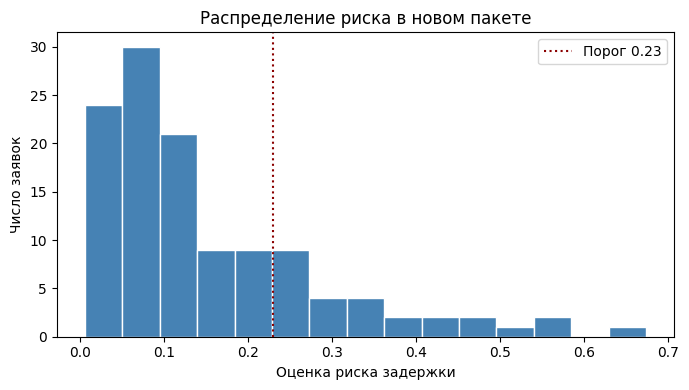

In [22]:
# Шаг М2.06.22 — Распределение оценок риска
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(batch_result['риск_задержки'], bins=15, color='steelblue', edgecolor='white')
ax.axvline(threshold, color='darkred', linestyle=':', label=f'Порог {threshold:.2f}')
ax.set(xlabel='Оценка риска задержки', ylabel='Число заявок',
       title='Распределение риска в новом пакете')
ax.legend()
fig.tight_layout()
plt.show()

**Размеры очереди и пустоты**

Показываем четыре агрегата: число заявок, средний риск, долю сигналов и долю строк хотя бы с одним пропуском. Это обзор текущего пакета для диагностики, без попытки выдать его за качество классификации.

In [23]:
# Шаг М2.06.23 — Размеры очереди и пустоты
summary = pd.Series({
    'заявок': len(batch),
    'средний_риск': batch_result['риск_задержки'].mean(),
    'доля_сигналов': batch_result['передать_на_обработку'].mean(),
    'доля_строк_с_пропуском': checked_batch.isna().any(axis=1).mean(),
    'незнакомых_категорий': sum(unknown_count.values())
}, name='наблюдение_без_меток')
display(summary)

заявок                    120.000000
средний_риск                0.150679
доля_сигналов               0.100000
доля_строк_с_пропуском      0.108333
незнакомых_категорий        1.000000
Name: наблюдение_без_меток, dtype: float64

**Проверка диагностического журнала**

Сбрасываем буфер журнала и показываем только последние несколько строк. В них есть запись о сохранении, успешных пакетах и обработанных отказах. Значений заказов в журнале нет; файлы старше тридцати дней удаляются при старте следующего запуска.

In [24]:
# Шаг М2.06.24 — Проверка диагностического журнала
for active_handler in logger.handlers:
    active_handler.flush()
recent_logs = log_path.read_text(encoding='utf-8').splitlines()[-6:]
for line in recent_logs:
    print(line)
assert all('request_id' not in line and 'customer_id' not in line for line in recent_logs)

2026-10-19 15:02:24,453 WARNING Отклонена схема: отсутствуют=['distance_km'], лишние=[]
2026-10-19 15:02:24,454 WARNING Отклонено нечисловое поле: items_count
2026-10-19 15:02:24,457 WARNING Отклонено значение вне диапазона: order_hour
2026-10-19 15:02:24,457 WARNING Отклонена схема: повторяющиеся имена колонок
2026-10-19 15:02:24,479 INFO Прогноз: строк=8, сигналов=0, пропусков=4, неизвестных_категорий={'city': 1, 'product_category': 0, 'delivery_type': 0, 'weather_forecast': 0, 'is_weekend': 0}
2026-10-19 15:02:24,507 INFO Прогноз: строк=120, сигналов=12, пропусков=14, неизвестных_категорий={'city': 1, 'product_category': 0, 'delivery_type': 0, 'weather_forecast': 0, 'is_weekend': 0}


Мы получили пакетные вероятности и список действий, записали агрегаты и проверили диагностический журнал. Все эти наблюдения доступны до появления целевой метки. Следующий раздел закрепит границу между инженерной проверкой работы файла и статистической оценкой модели.

## 5. Контроль результата и границы применения

Закрепляем, что артефакт принимает только признаки, выдаёт конечные вероятности от нуля до единицы и не требует исходов. Проверка стабильности и схемы не заменяет будущую проверку качества на зрелых метках. Упражнения выполнены непосредственно в ноутбуке, с ожидаемым результатом в сохранённом выводе.

**Задание: инварианты прогноза**

Решение задания проверяет границы вероятностей, размер ответа и потолок числа действий. Такие свойства можно проверить сразу, без меток. Они помогают поймать повреждённую сериализацию или ошибку пакетной функции.

In [25]:
# Шаг М2.06.25 — Задание: инварианты прогноза
assert len(batch_result) == len(batch)
assert batch_result['риск_задержки'].between(0, 1).all()
assert np.isfinite(batch_result['риск_задержки']).all()
assert int(batch_result['передать_на_обработку'].sum()) <= int(np.floor(len(batch) * capacity_share))
print('Инварианты пройдены для', len(batch_result), 'заявок')

Инварианты пройдены для 120 заявок


**Задание: цель во входе запрещена**

Пробуем передать искусственный столбец `late_delivery` в новый пакет. Проверка схемы должна отклонить его как лишний, даже если кто-то случайно приложил известные исходы. Так контракт предотвращает возврат утечки в момент применения.

In [26]:
# Шаг М2.06.26 — Задание: цель во входе запрещена
with_target = batch.copy()
with_target['late_delivery'] = 0
try:
    apply_saved_solution(with_target, loaded, loaded_meta)
except ValueError as error:
    print('Ожидаемый отказ:', error)
else:
    raise AssertionError('Лишняя цель была принята')

Ожидаемый отказ: Схема: отсутствуют []; лишние ['late_delivery']


**Задание: что можно узнать через семь дней**

Код перечисляет наблюдения, доступные сейчас, и показатели, которые потребуют зрелых меток. Это решение методического задания: разделить мониторинг входа и результата модели. Для нового пакета второй список пока не вычисляется.

In [27]:
# Шаг М2.06.27 — Задание: что можно узнать через семь дней
available_now = ['число заявок', 'пропуски и неизвестные категории',
                 'распределение риска', 'число действий']
after_labels = ['AP', 'precision и recall', 'Brier и калибровка',
                'матрица ошибок']
print('Сейчас:', '; '.join(available_now))
print('После появления меток:', '; '.join(after_labels))
assert 'late_delivery' not in batch.columns

Сейчас: число заявок; пропуски и неизвестные категории; распределение риска; число действий
После появления меток: AP; precision и recall; Brier и калибровка; матрица ошибок


Инварианты и отказы схемы прошли, а список будущих метрик отделён от мониторинга без меток. Артефакт пригоден для локального учебного применения к новым пакетам заданной схемы; работа в другой версии окружения или при изменившейся логистике потребует повторной проверки.

## Полученный результат

Практический результат — локальные файлы `outputs/06/delivery_pipeline.joblib` и `delivery_metadata.json`. Первый содержит всю подготовку и классификатор, второй описывает схему, версии среды, модель, периоды, порог, лимит мощности и ограничения. Проверка round-trip показала совпадение вероятностей до и после загрузки, а пакетная проверка — их стабильность при разбиении входа. Новые заявки передаются без цели и постфактум полей; ошибочные типы, диапазоны и пустые обязательные поля отклоняются, неизвестные категории проходят с диагностическим сигналом.

Второй результат — минимальный мониторинг: пропуски, неизвестные категории, распределение риска, число действий и журнал отказов. Качество нового пакета по этим данным оценить нельзя до появления истинных меток. Сохранённый joblib следует загружать только из доверенного источника и повторно проверять при изменении версий библиотек или входной схемы.

## Документация

[Сохранение моделей scikit-learn](https://scikit-learn.org/1.8/model_persistence.html)

[Pipeline](https://scikit-learn.org/1.8/modules/generated/sklearn.pipeline.Pipeline.html)

[OneHotEncoder](https://scikit-learn.org/1.8/modules/generated/sklearn.preprocessing.OneHotEncoder.html)

[ColumnTransformer](https://scikit-learn.org/1.8/modules/generated/sklearn.compose.ColumnTransformer.html)